# Notebook 01 — Machine Learning Fundamentals & Model Selection

**Project:** ML Model Benchmark Lab  
**Purpose:** Build a practical reference for understanding machine learning, selecting suitable model families, and preparing for fair experiments.

> **Learning approach:** 
* Focus on concepts that help you make good decisions: 
* Identify the problem
* understand the data, 
* Establish a baseline 
* Evaluate fairl and interpret errors. 

## Learning outcomes

By the end of this notebook, you should be able to:

1. Explain machine learning in your own words.
2. Distinguish supervised, unsupervised, semi-supervised, and reinforcement learning.
3. Recognize classification, regression, clustering, dimensionality reduction, and anomaly detection tasks.
4. Explain the intuition, strengths, weaknesses, and typical use cases of major ML models.
5. Describe a reliable ML workflow 
6. Select suitable evaluation metrics and recognize overfitting, underfitting, and data leakage.
7. Write a reasoned first-choice model shortlist for a new dataset.


## Contents

1. What is machine learning?
2. Types of machine learning
3. Types of ML problems
4. Model families and when to try them
5. The end-to-end ML workflow
6. Train/validation/test splits and the 80/20 approach
7. Metrics, overfitting, and common pitfalls
8. A practical model-selection decision framework

---

## 1. What is machine learning?

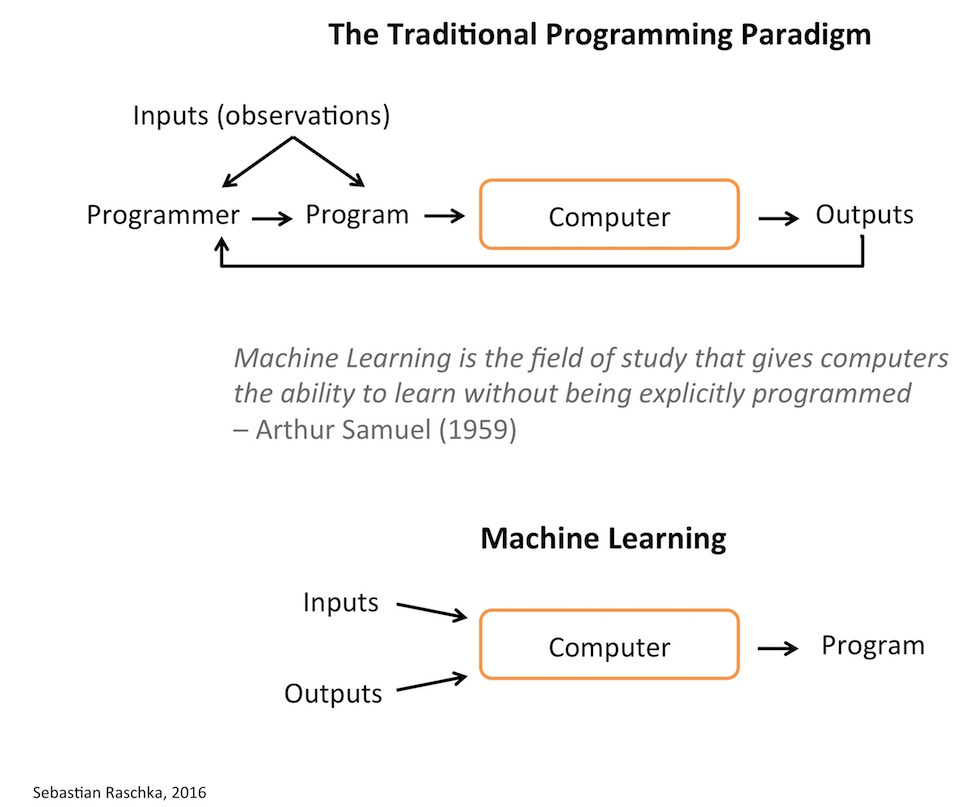

**Machine learning (ML)** is a field of computing in which algorithms learn patterns from data and use those patterns to make predictions, decisions, or discover structure.

### Traditional programming vs. machine learning

In a traditional rule-based program, a developer writes the rules explicitly:

- **Traditional programming:** rules + input → output
- **Supervised ML:** examples of inputs and correct outputs → learned model
- **Prediction:** new input + trained model → predicted output

For example, writing every possible rule for identifying spam emails is difficult. Instead, a supervised learning algorithm can learn patterns from emails labeled *spam* or *not spam*.

### Core vocabulary

| Term | Meaning | Example in house-price prediction |
|---|---|---|
| Dataset | Collection of examples | Records of houses |
| Sample / observation | One row or example | One house |
| Feature (`X`) | Input information used by a model | Area, rooms, location |
| Target / label (`y`) | What the model should predict | Sale price |
| Algorithm | Learning procedure | Linear Regression |
| Model | Learned mapping after training | Fitted price predictor |
| Training | Fitting a model using data | Learning relationships from known houses |
| Inference / prediction | Applying a trained model to new inputs | Estimating a new house's price |
| Generalization | Performing well on unseen examples | Predicting prices for houses not used in training |

**Important distinction:** An algorithm is the learning procedure; a trained model is the result of applying that procedure to data.



---

## 2. Types of machine learning

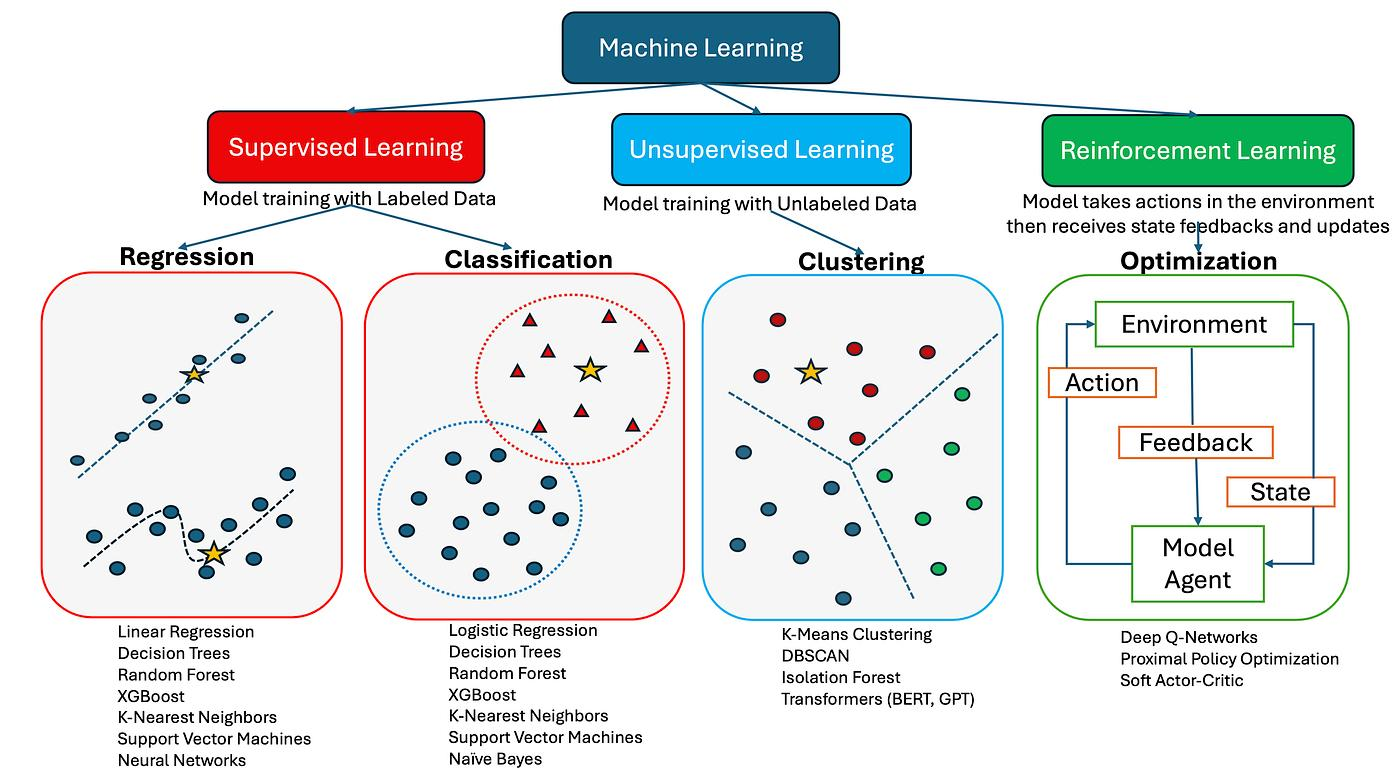

### 2.1 Supervised learning

The training data includes inputs `X` and known target values `y`. The model learns to predict targets for new inputs.

Common tasks:
- **Classification:** predict a category, such as spam/not spam.
- **Regression:** predict a numeric quantity, such as delivery time.

Typical algorithms: Logistic Regression, Linear Regression, Decision Trees, Random Forests, Support Vector Machines, K-Nearest Neighbors, and Gradient Boosting.

### 2.2 Unsupervised learning

The data has no target labels supplied for the learning task. The goal is to discover structure, groups, lower-dimensional representations, or unusual observations.

Examples:
- Group customers with similar behavior.
- Explore whether observations form clusters.
- Compress many correlated features into fewer dimensions.

Typical algorithms: K-Means, DBSCAN, hierarchical clustering, and Principal Component Analysis (PCA).

**Caution:** A cluster is a mathematical grouping, not automatically a meaningful real-world category. You must interpret and validate it.



### 2.3 Reinforcement learning

An agent interacts with an environment, takes actions, and receives rewards or penalties. It learns a policy for choosing actions over time.

Examples: game-playing agents, robotics, and some sequential resource-allocation problems.




---

## 3. Types of ML problems

Before selecting an algorithm, identify the task. 

| Problem | What is predicted or discovered? | Example | Common starting points |
|---|---|---|---|
| Binary classification | One of two classes | Fraud / not fraud | Logistic Regression, linear SVM, tree ensembles |
| Multiclass classification | One of 3+ classes | Classify a digit from 0–9 | Logistic Regression, SVM, Random Forest |
| Multilabel classification | Multiple labels can be true at once | Tag an article with several topics | One-vs-rest models, classifier chains |
| Regression | Numeric value | Predict energy consumption | Linear Regression, Random Forest Regressor, Gradient Boosting |
| Clustering | Groups without known target labels | Customer segments | K-Means, DBSCAN, hierarchical clustering |
| Dimensionality reduction | A smaller representation of features | Visualize high-dimensional data | PCA, other embedding methods |
| Anomaly detection | Unusual observations | Detect suspicious transactions | Isolation Forest, One-Class SVM, domain rules |

### Classification vs. regression

- If the target is a category, it is generally a **classification** problem.
- If the target is a numeric quantity, it is generally a **regression** problem.

The data type alone does not determine the task. For example, an integer `1–5` might represent ordered categories (classification) or a numeric score (regression), depending on the question and assumptions.

### A note on model names

Some algorithms support more than one task:
- Decision Trees can classify or regress.
- Random Forests can classify or regress.
- Support Vector Machines have classification and regression variants (`SVC` and `SVR`).
- KNN can classify or regress.

K-Means, by contrast, is a clustering algorithm, not a supervised classifier.



---

## 4. Model families: how they work and when to try them

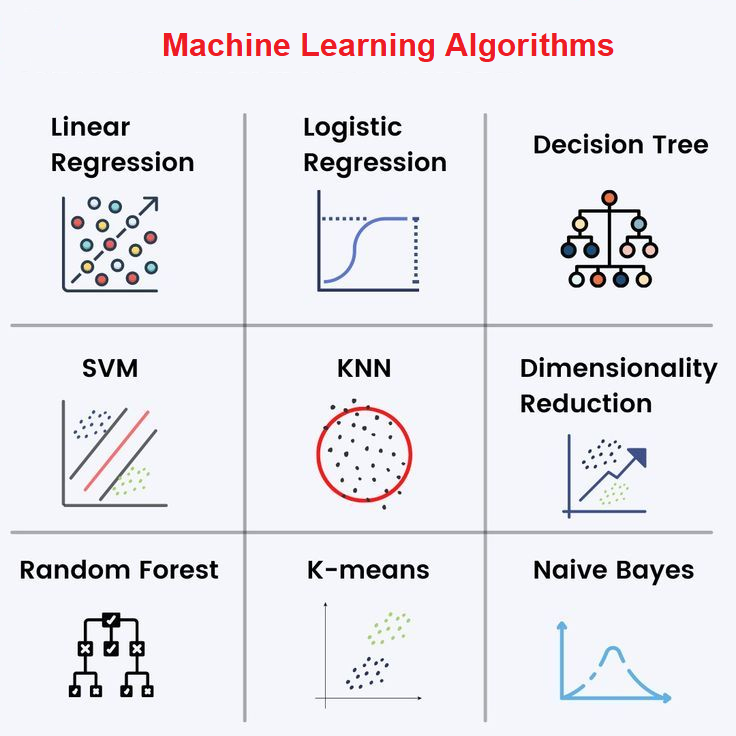

The goal here is **intuition and model selection**, not memorizing every formula. Begin with simple, interpretable baselines and compare them with more flexible models.

### 4.1 Linear Regression

**Task:** Regression.

**Intuition:** Fits a linear relationship between input features and a numeric target.

**Try it when:** You need a fast, interpretable baseline and a roughly linear relationship is plausible.

**Strengths:** Simple, fast, coefficients can be inspected.

**Limitations:** May miss nonlinear relationships; can be affected by outliers and correlated features.

**Questions to ask:** Are residuals patterned? Is the relationship approximately linear? Are predictions implausible outside the observed data range?

### 4.2 Logistic Regression

**Task:** Classification (binary or multiclass, depending on configuration).

**Intuition:** Models class probabilities using a linear combination of features and a link function.

**Try it when:** You need a strong baseline, fast training, and a relatively interpretable model.

**Strengths:** Efficient, often a useful baseline, supports probability estimates.

**Limitations:** Standard form has a linear decision boundary in the feature space; scaling often helps optimization.

**Useful with:** Numeric tabular data and text represented with TF-IDF features.

### 4.3 Decision Tree

**Task:** Classification or regression.

**Intuition:** Repeatedly splits the data using feature-based rules.

**Try it when:** You want nonlinear behavior and rules that can be inspected.

**Strengths:** Handles nonlinear relationships; little need for feature scaling; easy to visualize when small.

**Limitations:** A deep tree can overfit and small data changes can alter its structure.

**Controls to investigate:** `max_depth`, `min_samples_leaf`, and pruning.

### 4.4 Random Forest

**Task:** Classification or regression.

**Intuition:** Trains many decision trees on randomized samples/features and combines their predictions.

**Try it when:** You need a strong starting point for many tabular datasets and want to capture nonlinear interactions.

**Strengths:** Often robust; captures nonlinear patterns; usually needs little feature scaling.

**Limitations:** Larger and less directly interpretable than one small tree; can be costly with many trees or features.

**Questions to ask:** Does it improve on a single tree? How stable are results? Are feature-importance measures being interpreted carefully?

### 4.5 Gradient Boosting

**Task:** Classification or regression.

**Intuition:** Builds an ensemble sequentially, with later learners improving on errors or residual structure from earlier learners.

**Try it when:** You want to test powerful methods for structured/tabular data.

**Strengths:** Often highly competitive on tabular datasets.

**Limitations:** More tuning choices; can overfit if complexity and learning rate are poorly controlled; training can be slower.

**Examples:** Scikit-learn's `HistGradientBoostingClassifier` and `HistGradientBoostingRegressor`, as well as other gradient-boosting libraries.

### 4.6 Support Vector Machine (SVM)

**Task:** Classification (`SVC`) or regression (`SVR`).

**Intuition:** Finds a decision boundary with a large margin; kernels can represent nonlinear boundaries.

**Try it when:** The dataset is small or medium-sized and a margin-based method is worth testing.

**Strengths:** Can work well in high-dimensional feature spaces; kernels provide flexibility.

**Limitations:** Scaling is important; nonlinear kernels and hyperparameters require care; training may become expensive on large datasets.

**Variants:** A linear SVM is often useful for high-dimensional sparse text features; an RBF kernel can model nonlinear boundaries.

### 4.7 K-Nearest Neighbors (KNN)

**Task:** Classification or regression.

**Intuition:** Uses nearby training examples to predict a label or value.

**Try it when:** Similarity in feature space is meaningful and the dataset is not too large.

**Strengths:** Simple to understand; little model-fitting work.

**Limitations:** Prediction can be expensive; scaling and distance choice matter; high-dimensional distances may become less informative.

**Controls to investigate:** Number of neighbors (`n_neighbors`), distance metric, and weighting.

### 4.8 Naive Bayes

**Task:** Classification.

**Intuition:** Uses Bayes' theorem with a conditional-independence assumption between features given the class.

**Try it when:** You need a fast baseline, especially for bag-of-words or TF-IDF text classification.

**Strengths:** Fast, works well in some high-dimensional text tasks, needs relatively little data.

**Limitations:** The independence assumption is often unrealistic; probability estimates can be imperfect.

**Variants:** Multinomial Naive Bayes is common for count-like text features; Gaussian Naive Bayes is designed for continuous features under a Gaussian assumption.

### 4.9 K-Means

**Task:** Unsupervised clustering.

**Intuition:** Assigns observations to one of `k` clusters by iteratively updating cluster centers.

**Try it when:** You want to explore compact, reasonably separated groups in numeric feature space.

**Strengths:** Simple and relatively fast.

**Limitations:** You must choose `k`; results depend on scaling and initialization; it favors roughly compact clusters and is sensitive to outliers.

### 4.10 DBSCAN

**Task:** Unsupervised clustering and noise identification.

**Intuition:** Groups points in dense regions and marks points in sparse regions as noise.

**Try it when:** You suspect clusters with irregular shapes and want to identify outliers.

**Strengths:** Does not require specifying the number of clusters in advance; can find non-spherical groups.

**Limitations:** Sensitive to `eps`, `min_samples`, feature scaling, and varying densities.

### 4.11 Principal Component Analysis (PCA)

**Task:** Dimensionality reduction.

**Intuition:** Finds directions that capture as much variance as possible using linear combinations of features.

**Try it when:** You want a compact representation, visualize high-dimensional data, or reduce correlated numeric features.

**Strengths:** Useful for exploratory analysis and some pipelines.

**Limitations:** Components can be difficult to interpret; high variance is not always the same as high predictive value; scaling may be important.

### 4.12 Neural Networks and Deep Learning

**Task:** Classification, regression, representation learning, and more.

**Intuition:** Learn layered transformations of input data by adjusting weights during training.

**Try it when:** You have enough data and compute, or work with complex modalities such as images, audio, or language.

**Strengths:** Flexible; central to modern vision, speech, and language systems.

**Limitations:** Can require more data, compute, tuning, and careful regularization; often harder to interpret.

**Practical rule:** Do not assume a neural network is the best starting point for a small tabular dataset. Begin with strong classical baselines and justify added complexity.

---
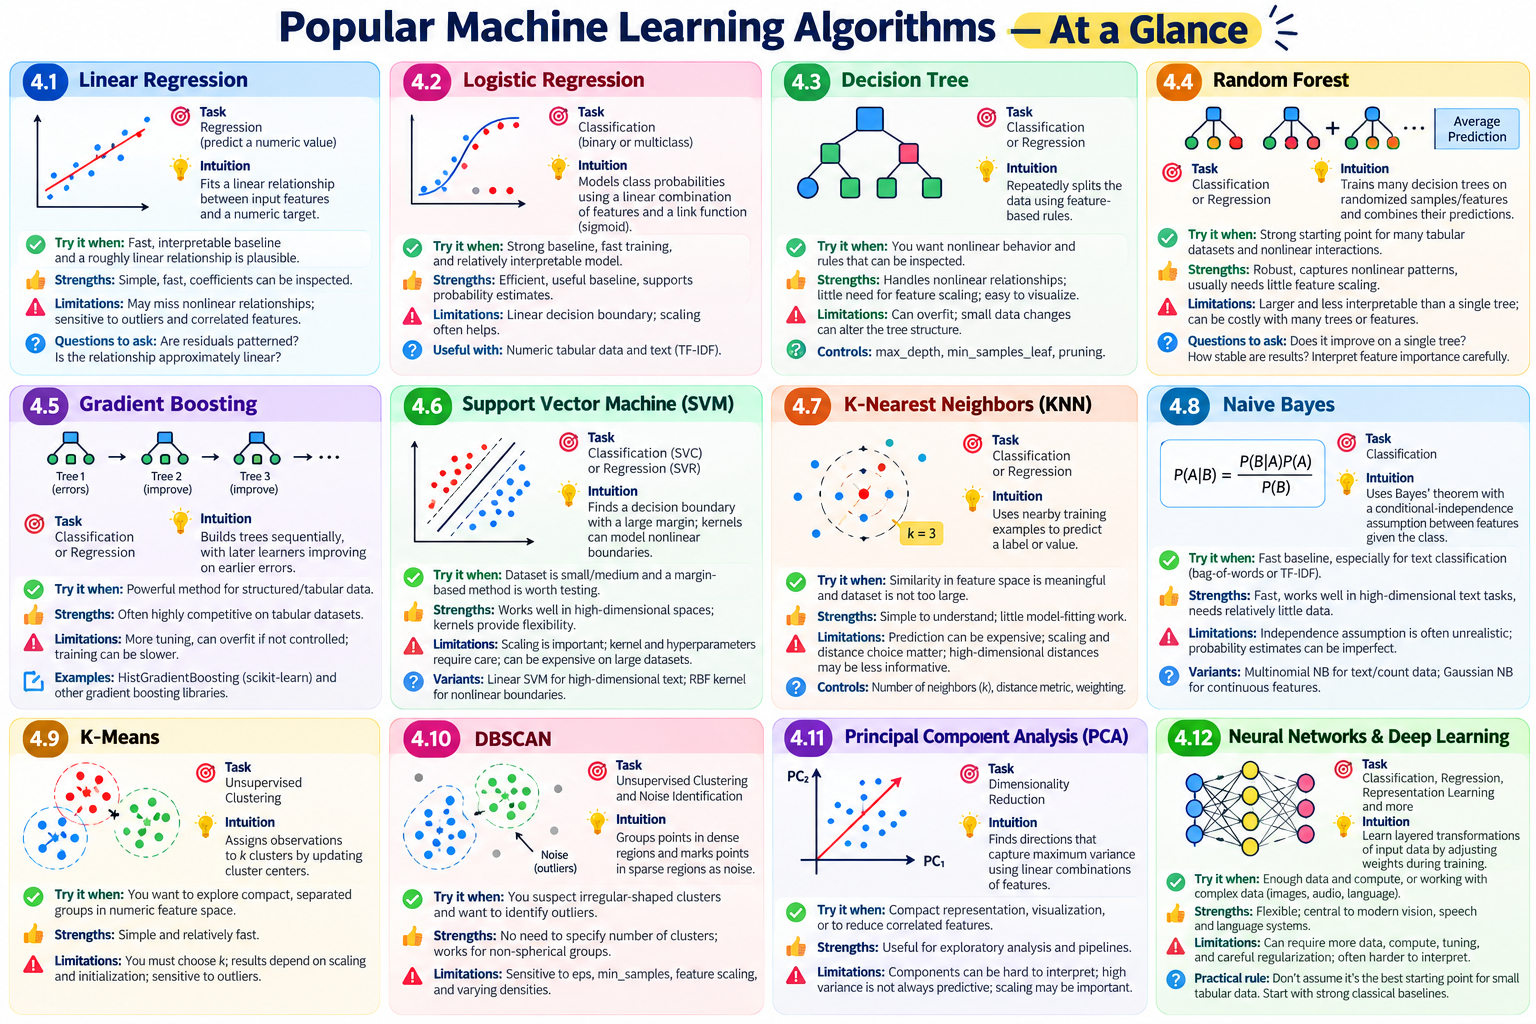

---

## 5. The end-to-end ML workflow

A practical ML project is more than choosing an algorithm.

1. **Define the problem:** What decision or prediction is needed? What does success mean?
2. **Collect and understand data:** Inspect rows, features, labels, missing values, class balance, and data provenance.
3. **Create a test set:** Reserve data for a final evaluation before fitting preprocessing or models.
4. **Build a baseline:** Use a simple rule or model to establish a reference point.
5. **Preprocess within the training workflow:** Impute missing values, encode categories, scale features, or select features without leaking test information.
6. **Train candidate models:** Start with a justified shortlist.
7. **Validate and tune:** Use cross-validation on training data to compare approaches and choose hyperparameters.
8. **Evaluate once on the held-out test set:** Report the final estimate using appropriate metrics.
9. **Analyze errors:** Inspect confusion matrices, residuals, class-specific performance, and failure cases.
10. **Communicate and maintain:** Document assumptions, limitations, reproducibility steps, and what should be monitored if deployed.

### Baseline first

A baseline answers: *Does this model provide value beyond a simple reference?*

Examples:
- Classification: `DummyClassifier`
- Regression: `DummyRegressor`

A complex model that barely improves on a baseline may not be worth its cost.

---

## 6. The 80/20 train-test split and validation

The **80/20 split** usually means allocating approximately:
- **80% for training and model development**
- **20% for final testing**

The exact split depends on dataset size, data structure, and the evaluation goal. It is not a universal law.

### What each partition is for

| Partition | Purpose | Can it influence model choices? |
|---|---|---|
| Training set | Fit model parameters | Yes |
| Validation data / cross-validation folds | Compare models and tune hyperparameters | Yes |
| Test set | Estimate performance of the final selected approach on unseen data | Ideally, no—until final evaluation |

A common small-data workflow is:
1. Split data into 80% training and 20% testing.
2. Use cross-validation only inside the 80% training partition.
3. Select the model and settings based on training/CV results.
4. Refit the selected pipeline on all training data.
5. Evaluate on the 20% test set once.

If you repeatedly inspect the test score and adjust your model based on it, the test set gradually becomes part of model selection and is no longer a clean final evaluation.


---

## 7. Evaluation metrics and common pitfalls

### 7.1 Classification metrics

Consider a binary classifier:

- **True Positive (TP):** correctly predicts the positive class.
- **True Negative (TN):** correctly predicts the negative class.
- **False Positive (FP):** predicts positive when the truth is negative.
- **False Negative (FN):** predicts negative when the truth is positive.

| Metric | Intuition | Use it when… |
|---|---|---|
| Accuracy | Fraction of predictions that are correct | Classes and error costs make it a meaningful summary |
| Precision | Of predicted positives, how many are truly positive? | False alarms are costly |
| Recall / sensitivity | Of actual positives, how many are detected? | Missing positive cases is costly |
| Specificity | Of actual negatives, how many are correctly rejected? | Correctly ruling out negatives matters |
| F1-score | Harmonic mean of precision and recall | You want a single balance of precision and recall |
| ROC-AUC | Ranking ability across thresholds | You want threshold-independent ranking information |
| Balanced accuracy | Average recall across classes in binary classification; generalized across classes | Class frequencies are unequal |

No metric is universally best. Choose metrics based on the real costs of different errors. For multiclass tasks, macro-averaged metrics give each class equal weight, whereas weighted averages account for class support.

### 7.2 Regression metrics

| Metric | Intuition | Caution |
|---|---|---|
| MAE | Average absolute prediction error | Treats error magnitudes linearly |
| MSE | Average squared error | Penalizes large errors more heavily |
| RMSE | Square root of MSE, in target units | Large errors have more influence |
| R² | Relative fit compared with predicting the target mean | Can be negative on test data; is not a percentage accuracy |

### 7.3 Overfitting and underfitting

- **Underfitting:** the model is too limited or poorly configured to capture important patterns. It often performs poorly on both training and validation data.
- **Overfitting:** the model learns patterns specific to training data, including noise. Training performance is strong but validation/test performance is weaker.
- **Good generalization:** performance remains useful on representative unseen data.

Ways to address overfitting include simpler models, regularization, pruning, more representative data, appropriate feature selection, and careful cross-validation. The right solution depends on the cause.

### 7.4 Common pitfalls

**Data leakage:** Information unavailable at prediction time enters training or model selection. Examples include scaling the full dataset before cross-validation, using a feature derived from the target, or allowing future information into a forecasting model.

**Class imbalance:** A model can achieve high accuracy by mostly predicting the majority class. Check per-class metrics and the confusion matrix.

**Inappropriate split:** Random splitting can give overly optimistic results when observations are related, repeated by person, or ordered in time.

**Over-tuning:** Trying many settings and reporting only the best validation score can overfit the validation process. Keep a final test set untouched.

**Unfair comparison:** Models should be evaluated using the same data partitions, clearly documented preprocessing, comparable metrics, and appropriate tuning effort.

**Correlation is not causation:** A predictive model can exploit associations without showing that changing a feature will cause the outcome to change.


---

## 8. A practical model-selection decision framework

Use this sequence whenever you start a new ML project.

### Step 1 — Identify the target

- Numeric quantity → consider regression.
- Category → consider classification.
- No target labels and you want groups → consider clustering.
- Need a smaller representation → consider dimensionality reduction.
- Need unusual-case detection → consider anomaly detection.

### Step 2 — Understand the data

Ask:
- How many samples and features are available?
- Are features numeric, categorical, text, images, or mixed?
- Are labels balanced?
- Are there missing values, outliers, repeated observations, or time dependencies?
- What information would genuinely be available at prediction time?

### Step 3 — Set constraints

Consider:
- Interpretability and explainability
- Training and prediction latency
- Memory and compute
- Need for calibrated probabilities
- Cost of false positives versus false negatives
- Reproducibility and maintenance

### Step 4 — Build a small, justified shortlist

For a standard numeric tabular classification task, a useful first shortlist might be:
1. Dummy Classifier (baseline)
2. Logistic Regression (linear baseline)
3. Decision Tree (interpretable nonlinear model)
4. Random Forest (tree ensemble)
5. SVM or KNN (different learning mechanism)

Do not automatically use every algorithm. If the problem is regression, use regression estimators. If it is clustering, supervised classification scores are not appropriate unless you have a valid external evaluation setup.

### Step 5 — Compare fairly

- Use a suitable split strategy.
- Put preprocessing in pipelines.
- Use cross-validation for model comparison.
- Choose metrics based on the task and error costs.
- Evaluate the selected approach on the untouched test set.
- Report both performance and relevant costs.

### Step 6 — Explain the choice

A strong model-selection statement looks like this:

> “I selected these candidate models because they represent different assumptions and levels of complexity. I used the same training partitions and primary metric to compare them. The final choice considers test performance, cross-validation variability, computational cost, and interpretability—not accuracy alone.”

That is a research-oriented justification. It is stronger than saying, “I chose Random Forest because it is usually accurate.”
